<a href="https://colab.research.google.com/github/Adi-Luhung/Pembelajaran-Mesin-2026/blob/main/JS09_Klasifikasi_kNN_NaiveBayes_terisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS09 - Klasifikasi (kNN dan Naive Bayes)
Praktikum Machine Learning

**Isi notebook:**
- Praktikum 1 : k-Nearest Neighbors (`iris.csv`)
- Praktikum 2 : Naive Bayes dengan data dummy
- Praktikum 3 : Naive Bayes dengan data multimoda (`spam.csv`)
- Tugas 1 : kNN untuk klasifikasi suara male/female (`voice.csv`)
- Tugas 2 : Multinomial Naive Bayes `CountVectorizer` vs `TF-IDF` (`spam.csv`)

> Jalankan sel dari atas ke bawah. Sel pertama akan meminta upload `iris.csv`, `spam.csv`, dan `voice.csv`.

In [1]:
import os
if not all(os.path.exists(f) for f in ['iris.csv', 'spam.csv', 'voice.csv']):
    from google.colab import files
    files.upload()

print(sorted(f for f in os.listdir('.') if f.endswith('.csv')))

Saving iris.csv to iris.csv
Saving spam.csv to spam.csv
Saving voice.csv to voice.csv
['iris.csv', 'spam.csv', 'voice.csv']


---
# Praktikum 1 - k-Nearest Neighbors (kNN)
## Langkah 1 - Load Data

In [2]:
# Load data
import pandas as pd
data = pd.read_csv('iris.csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Langkah 2 - Eksplorasi Data
Cek struktur data informasi deskriptif data

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [4]:
data.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [5]:
data['species'].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


## Langkah 3 - Visualisasi Data
Visualisasi untuk mengetahui distribusi dan korelasi setiap fitur terhadap label.

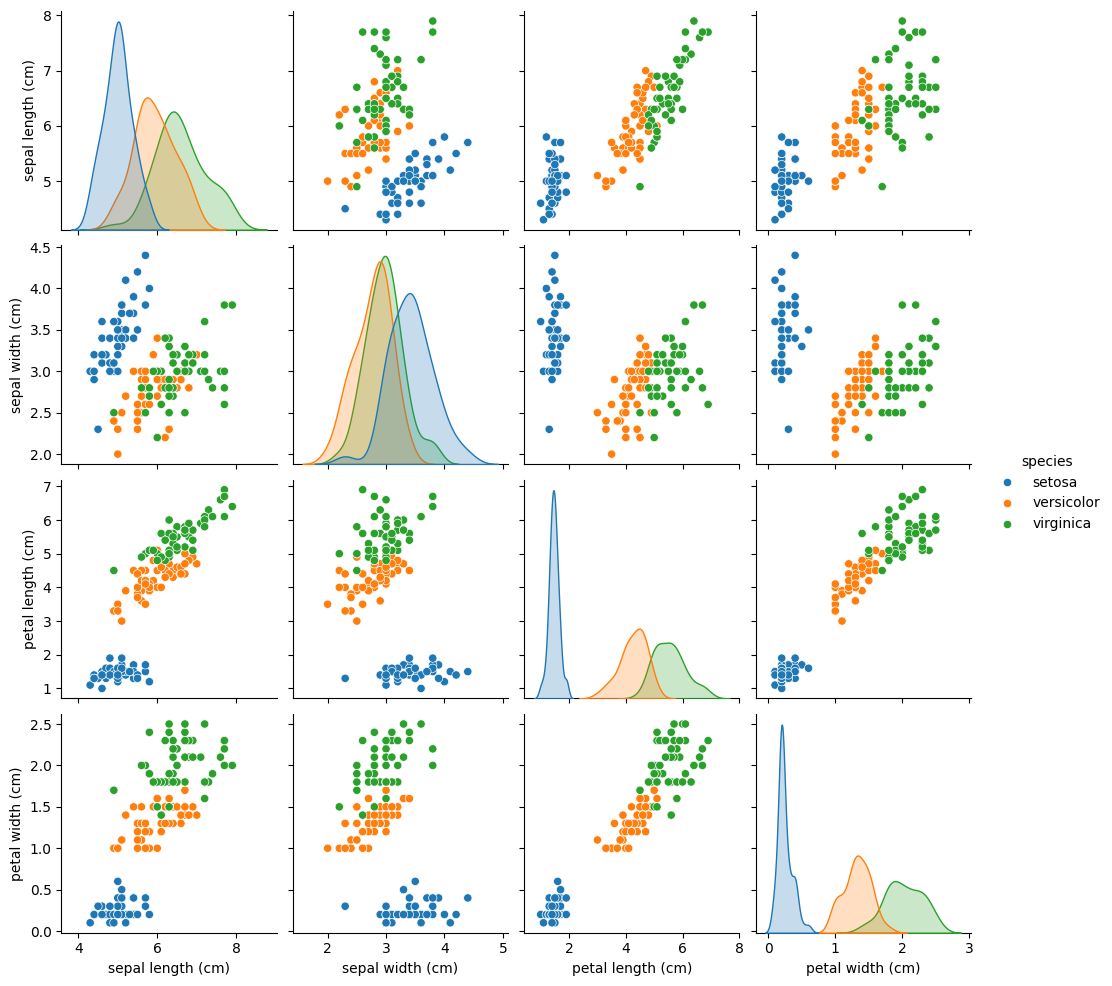

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

## Langkah 4 - Preprocessing
Memisahkan label dengan fitur, lalu standardisasi fitur.

> Pada Iris Dataset seluruh fitur sudah dalam satuan yang sama (cm).

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi (fit hanya pada data train)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Langkah 5 - Buat Model kNN

In [8]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

## Langkah 6 - Evaluasi Model kNN

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Apakah nilai k=3 memang yang terbaik? Evaluasi setiap nilai k.

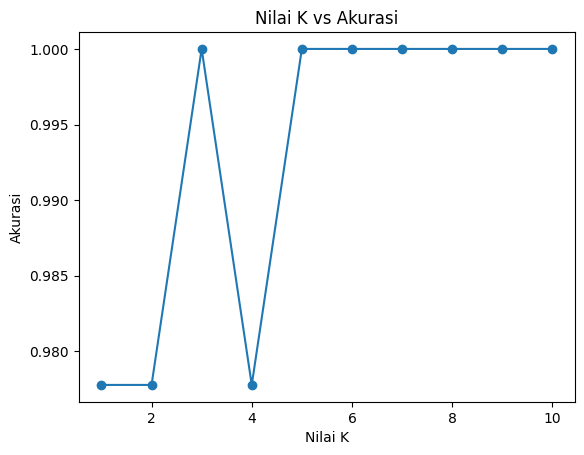

In [10]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

Perbandingan akurasi data training dan data testing untuk tiap nilai k.

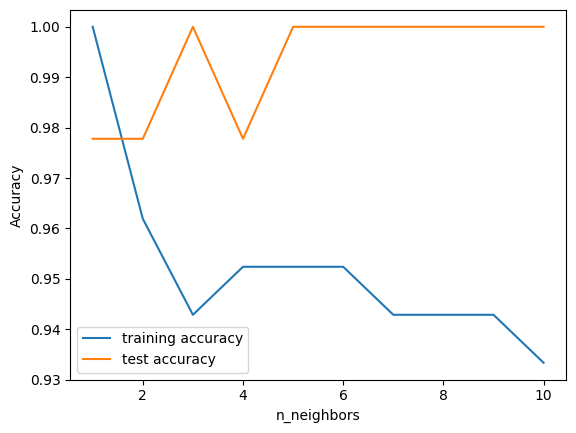

In [11]:
train_acc, test_acc = [], []
neighbors = range(1, 11)
for k in neighbors:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.plot(neighbors, train_acc, label='training accuracy')
plt.plot(neighbors, test_acc, label='test accuracy')
plt.ylabel('Accuracy')
plt.xlabel('n_neighbors')
plt.legend()
plt.show()

---
# Praktikum 2 - Klasifikasi Naive Bayes dengan Data Dummy
## Langkah 1 - Buat Dataset Dummy

In [12]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[ 44 131]
 [100 168]
 [ 92 160]
 [163  92]
 [179 259]
 [139  48]
 [ 94  63]
 [  1 102]
 [ 87  97]
 [ 26  85]
 [  4  10]
 [172 180]
 [149 188]
 [119 132]
 [ 84  73]
 [ 61  67]
 [ 91  99]
 [ 50  65]
 [ 28  49]
 [ 28  18]
 [ 44  36]
 [147 113]
 [ 68  64]
 [155  83]
 [ 82   9]
 [104  38]
 [ 85 229]
 [ 78  24]
 [ 80 120]
 [ 98  32]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


## Langkah 2 (Opsional) - Membuat DataFrame

In [13]:
import pandas as pd

# Reshape label y menjadi 2D agar bisa digabung dengan X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y
data = np.concatenate((X, y_new), axis=1)

# Nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

df = pd.DataFrame(data, columns=nama_kolom)
df.head()

,Fitur 1,Fitur 2,Label
0,44,131,0
1,100,168,0
2,92,160,0
3,163,92,0
4,179,259,0


## Langkah 3 (Opsional) - Labeling

In [14]:
labels = {
    1: 'Kelas A',
    0: 'Kelas B'
}

df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)
df_label.head()

,Fitur 1,Fitur 2,Label
0,44,131,Kelas B
1,100,168,Kelas B
2,92,160,Kelas B
3,163,92,Kelas B
4,179,259,Kelas B


## Langkah 4 - Visualisasi Data

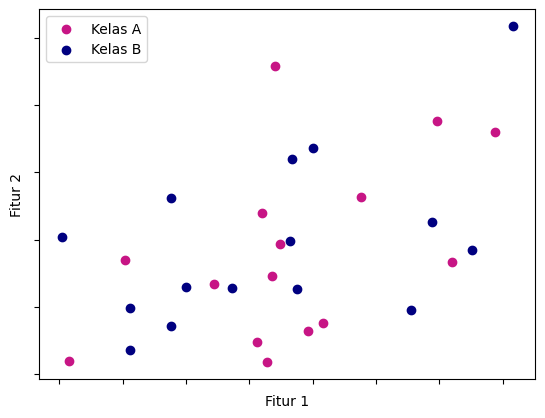

In [15]:
import matplotlib.pyplot as plt

colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

gb = df_label.groupby('Label')
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

## Langkah 5 - Model Multinomial Naive Bayes
Multinomial NB dirancang untuk fitur yang bersifat diskrit (misal jumlah kata). Di sini dicoba pada data kontinu sebagai pembelajaran.

In [16]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.5238095238095238
Hasil akurasi data test: 0.3333333333333333


## Langkah 6 - Model Gaussian Naive Bayes
Gaussian NB lebih cocok untuk data kontinu karena memakai distribusi normal.

In [17]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()

# Split data sama dengan model multinomial
gnb.fit(X_train, y_train)

y_train_pred_gnb = gnb.predict(X_train)
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

y_test_pred_gnb = gnb.predict(X_test)
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.5714285714285714
Hasil akurasi data test (Gaussian): 0.2222222222222222


---
# Praktikum 3 - Klasifikasi Naive Bayes dengan Data Multimoda (SMS Spam)
## Langkah 1 - Load Data

In [18]:
import numpy as np
import pandas as pd

# encoding latin-1 diperlukan karena ada karakter non-UTF8
df = pd.read_csv('spam.csv', encoding='latin-1')
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Langkah 2 - Preprocessing
2a. Drop kolom tidak terpakai, 2b. Rename kolom, 2c. Inspeksi data, 2d. Encode label, 2e. Pisahkan fitur dan label.

In [19]:
# 2a. Drop 3 kolom terakhir
df = df.drop(df.iloc[:, 2:], axis=1)

# 2a'. Ubah nama kolom v1 (label) dan v2 (teks sms)
df.columns = ['Labels', 'SMS']
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [20]:
# 2b. Inspeksi data
print(df['Labels'].value_counts())
print('\n')
print(df.info())
print('\n')
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


In [21]:
# 2c. Encode label
new_labels = {
    'spam': 1,
    'ham': 0
}
df['Labels'] = df['Labels'].map(new_labels)
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [22]:
# 2d. Pisahkan fitur dengan label
X = df['SMS'].values
y = df['Labels'].values

## Langkah 3 - Ekstraksi Fitur (Bag of Words)
Split dulu, baru transformasi, untuk mencegah *leaking information*.

In [23]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

In [24]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


## Langkah 4 - Training dan Evaluasi Model (Multinomial NB)

In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

y_pred_train = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_pred_train)

y_pred_test = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_pred_test)

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


---
# Tugas 1 - kNN pada `voice.csv`
1. Buat model klasifikasi kNN untuk mengklasifikasikan suara `male` dan `female`.
2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal. Fitur apa saja yang digunakan untuk hasil terbaik?
3. Berdasarkan fitur pada nomor 2, berapa nilai k terbaik? Lampirkan grafik analisis dan alasan.

## 1.1 Load dan eksplorasi data

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

voice = pd.read_csv('voice.csv')
print('Shape :', voice.shape)
voice.head()

Shape : (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [27]:
voice.info()
print('\nMissing value :', voice.isnull().sum().sum())
print('Data duplikat :', voice.duplicated().sum())
print('\nDistribusi label:')
print(voice['label'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

In [28]:
voice.describe().T

,count,mean,std,min,25%,50%,75%,max
meanfreq,3168.0,0.180907,0.029918,0.039363,0.163662,0.184838,0.199146,0.251124
sd,3168.0,0.057126,0.016652,0.018363,0.041954,0.059155,0.067020,0.115273
median,3168.0,0.185621,0.036360,0.010975,0.169593,0.190032,0.210618,0.261224
Q25,3168.0,0.140456,0.048680,0.000229,0.111087,0.140286,0.175939,0.247347
Q75,3168.0,0.224765,0.023639,0.042946,0.208747,0.225684,0.243660,0.273469
IQR,3168.0,0.084309,0.042783,0.014558,0.042560,0.094280,0.114175,0.252225
skew,3168.0,3.140168,4.240529,0.141735,1.649569,2.197101,2.931694,34.725453
kurt,3168.0,36.568461,134.928661,2.068455,5.669547,8.318463,13.648905,1309.612887
sp.ent,3168.0,0.895127,0.044980,0.738651,0.861811,0.901767,0.928713,0.981997
sfm,3168.0,0.408216,0.177521,0.036876,0.258041,0.396335,0.533676,0.842936


Distribusi beberapa fitur terhadap label, dan korelasi antar fitur.

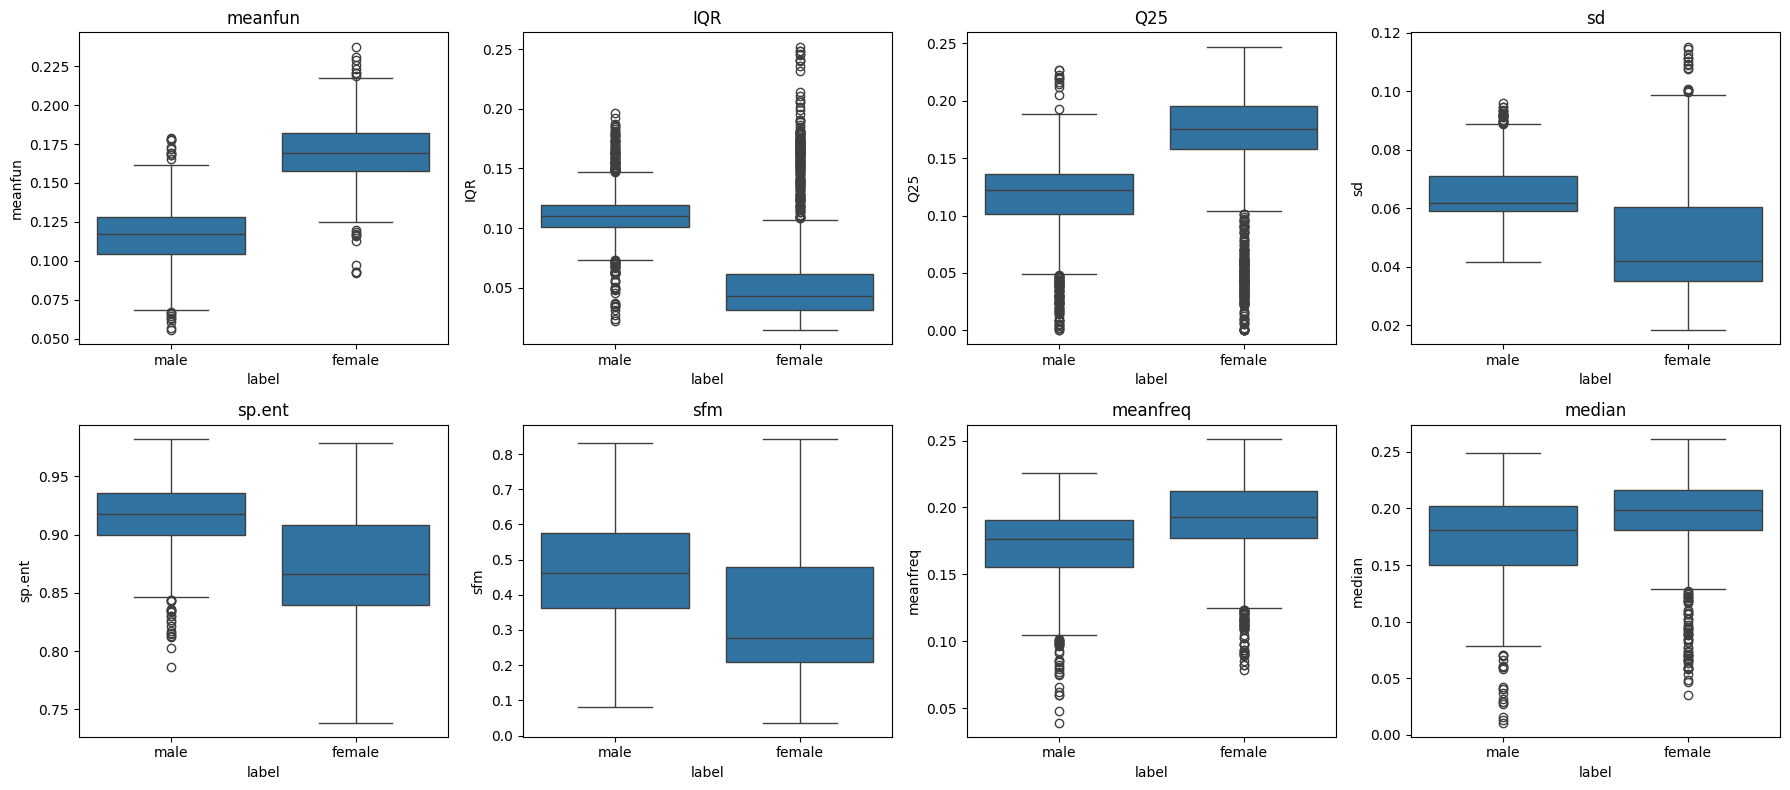

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), ['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent', 'sfm', 'meanfreq', 'median']):
    sns.boxplot(data=voice, x='label', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

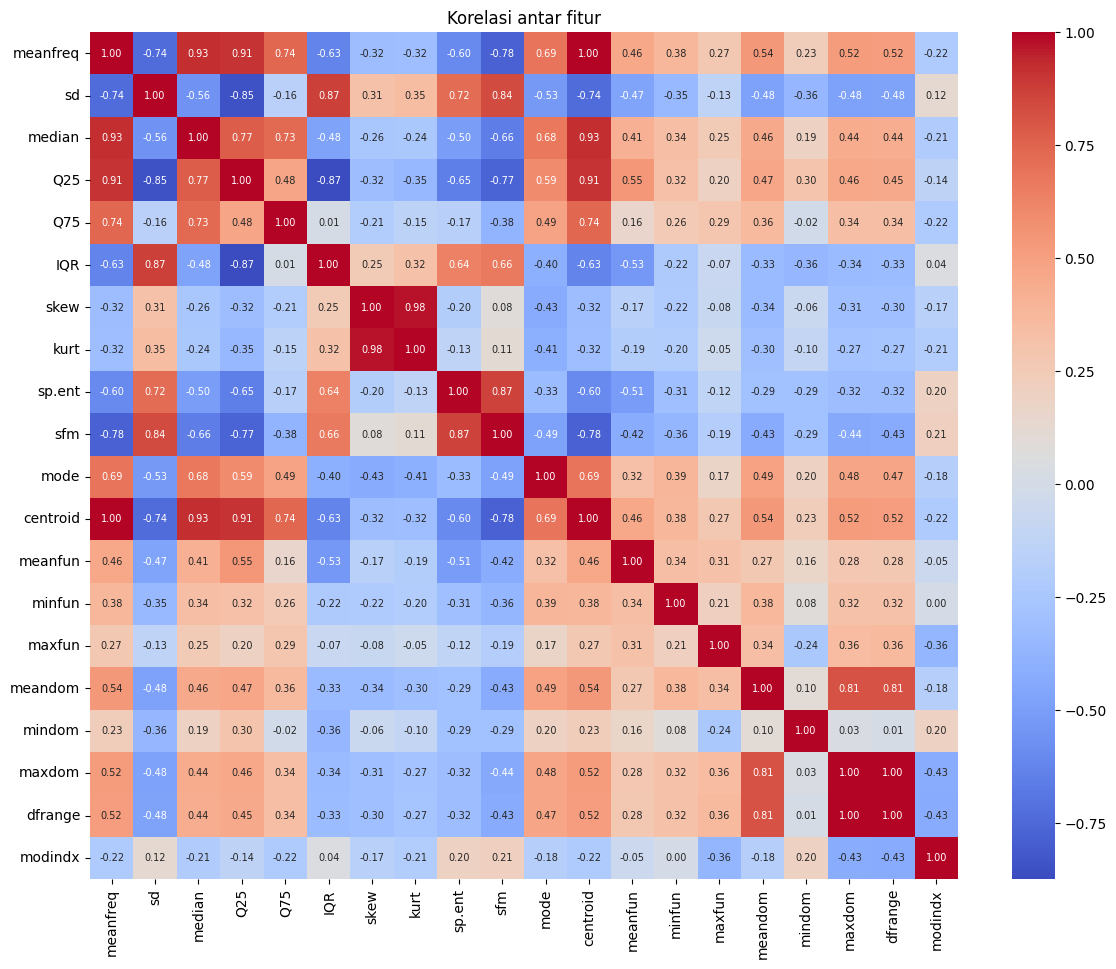

In [30]:
plt.figure(figsize=(14, 11))
sns.heatmap(voice.drop(columns='label').corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Korelasi antar fitur')
plt.show()

## 1.2 Preprocessing dan model baseline (semua fitur)
- Label di-encode: `male`=1, `female`=0
- Split 80:20 dengan `stratify` agar proporsi kelas terjaga
- Standardisasi **wajib** untuk kNN karena berbasis jarak (skala fitur sangat berbeda, mis. `kurt` vs `meanfun`)
- Scaler dipasang di dalam `Pipeline` supaya saat cross-validation tidak terjadi kebocoran informasi

In [31]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

X = voice.drop(columns='label')
y = voice['label'].map({'male': 1, 'female': 0})
all_features = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_score(cols, k=5):
    """Rata-rata akurasi cross-validation (5-fold) pada data TRAIN untuk subset fitur cols."""
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    return cross_val_score(pipe, X_train[cols], y_train, cv=skf, n_jobs=-1).mean()

def fit_eval(cols, k=5):
    """Latih pada train, kembalikan (akurasi train, akurasi test, model)."""
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    pipe.fit(X_train[cols], y_train)
    return pipe.score(X_train[cols], y_train), pipe.score(X_test[cols], y_test), pipe

# Baseline: semua fitur, k=5
tr, te, _ = fit_eval(all_features, k=5)
print(f'Baseline kNN (20 fitur, k=5) -> CV: {cv_score(all_features):.4f} | Train: {tr:.4f} | Test: {te:.4f}')

Train: (2534, 20) | Test: (634, 20)
Baseline kNN (20 fitur, k=5) -> CV: 0.9696 | Train: 0.9830 | Test: 0.9763


## 1.3 Pencarian fitur optimal
Seleksi fitur dilakukan **hanya dengan data train** (cross-validation), data test baru dipakai di akhir. Tiga pendekatan dibandingkan:

**(A)** Ranking fitur dengan *mutual information* lalu ambil top-N  
**(B)** *Forward selection* (greedy): tambah satu fitur yang paling menaikkan akurasi CV  
**(C)** Semua fitur (baseline)

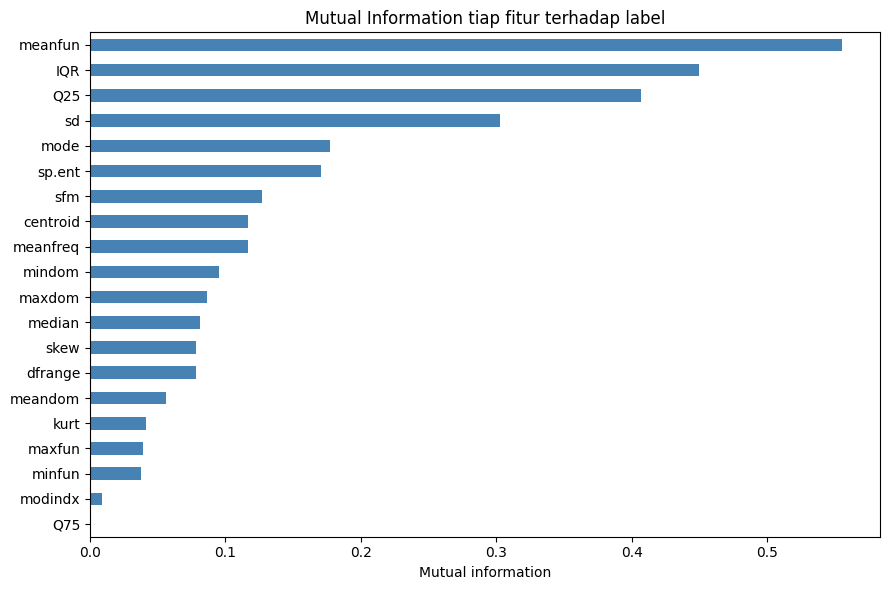

,0
meanfun,0.555423
IQR,0.449243
Q25,0.406964
sd,0.302449
mode,0.177453
sp.ent,0.170729
sfm,0.126971
meanfreq,0.116538
centroid,0.116538
mindom,0.095199


In [32]:
# (A) Ranking fitur berdasarkan mutual information terhadap label
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(X_train, y_train, random_state=42)
mi_series = pd.Series(mi, index=all_features).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
mi_series.sort_values().plot(kind='barh', color='steelblue')
plt.title('Mutual Information tiap fitur terhadap label')
plt.xlabel('Mutual information')
plt.tight_layout()
plt.show()
mi_series

Top-N terbaik: N = 9 | CV acc = 0.9791
Fitur: ['meanfun', 'IQR', 'Q25', 'sd', 'mode', 'sp.ent', 'sfm', 'meanfreq', 'centroid']


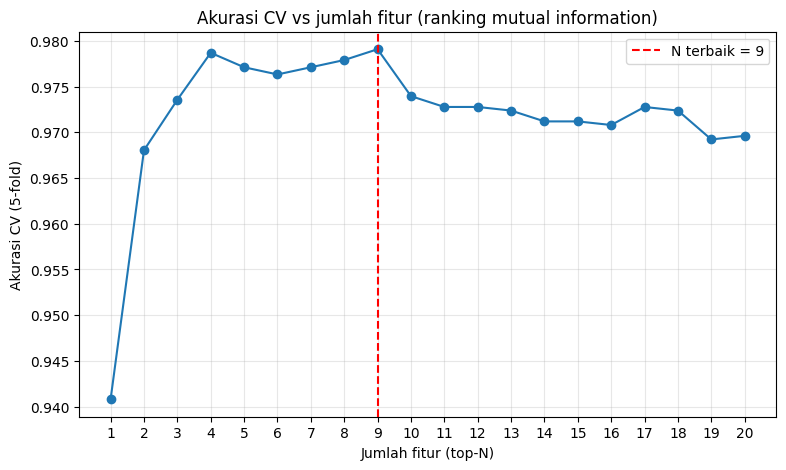

In [33]:
# Akurasi CV untuk top-N fitur menurut mutual information (N = 1..20), k = 5
ranked = list(mi_series.index)
n_range = range(1, len(ranked) + 1)
cv_topn = [cv_score(ranked[:n]) for n in n_range]

best_n = int(np.argmax(cv_topn)) + 1
print(f'Top-N terbaik: N = {best_n} | CV acc = {max(cv_topn):.4f}')
print('Fitur:', ranked[:best_n])

plt.figure(figsize=(9, 5))
plt.plot(n_range, cv_topn, marker='o')
plt.axvline(best_n, color='red', linestyle='--', label=f'N terbaik = {best_n}')
plt.title('Akurasi CV vs jumlah fitur (ranking mutual information)')
plt.xlabel('Jumlah fitur (top-N)')
plt.ylabel('Akurasi CV (5-fold)')
plt.xticks(list(n_range))
plt.grid(alpha=.3)
plt.legend()
plt.show()

 1 fitur | + meanfun   | CV acc = 0.9408
 2 fitur | + IQR       | CV acc = 0.9680
 3 fitur | + sfm       | CV acc = 0.9767
 4 fitur | + mode      | CV acc = 0.9807
 5 fitur | + skew      | CV acc = 0.9811
 6 fitur | + kurt      | CV acc = 0.9811
 7 fitur | + minfun    | CV acc = 0.9799
 8 fitur | + sp.ent    | CV acc = 0.9803
 9 fitur | + maxdom    | CV acc = 0.9807
10 fitur | + sd        | CV acc = 0.9807
11 fitur | + median    | CV acc = 0.9811
12 fitur | + maxfun    | CV acc = 0.9787
13 fitur | + Q25       | CV acc = 0.9771
14 fitur | + meanfreq  | CV acc = 0.9771
15 fitur | + centroid  | CV acc = 0.9775
16 fitur | + Q75       | CV acc = 0.9747
17 fitur | + dfrange   | CV acc = 0.9736
18 fitur | + modindx   | CV acc = 0.9728
19 fitur | + meandom   | CV acc = 0.9708
20 fitur | + mindom    | CV acc = 0.9696

Forward selection terbaik: 5 fitur -> ['meanfun', 'IQR', 'sfm', 'mode', 'skew']
CV acc = 0.9811


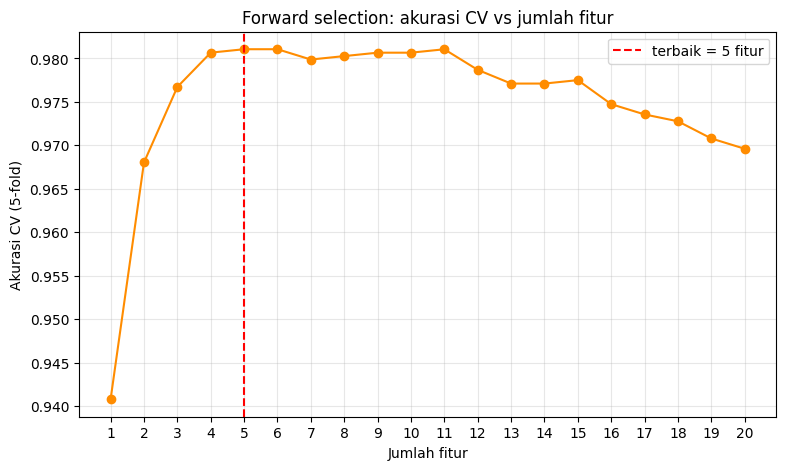

In [34]:
# (B) Forward selection greedy dengan kNN (k=5) dan akurasi CV sebagai kriteria
selected, remaining = [], all_features.copy()
fs_scores, fs_order = [], []

while remaining:
    cand = {f: cv_score(selected + [f]) for f in remaining}
    best_f = max(cand, key=cand.get)
    selected.append(best_f)
    remaining.remove(best_f)
    fs_scores.append(cand[best_f])
    fs_order.append(best_f)
    print(f'{len(selected):2d} fitur | + {best_f:9s} | CV acc = {cand[best_f]:.4f}')

best_fs_n = int(np.argmax(fs_scores)) + 1
fs_features = fs_order[:best_fs_n]
print(f'\nForward selection terbaik: {best_fs_n} fitur -> {fs_features}')
print(f'CV acc = {max(fs_scores):.4f}')

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(fs_scores) + 1), fs_scores, marker='o', color='darkorange')
plt.axvline(best_fs_n, color='red', linestyle='--', label=f'terbaik = {best_fs_n} fitur')
plt.title('Forward selection: akurasi CV vs jumlah fitur')
plt.xlabel('Jumlah fitur')
plt.ylabel('Akurasi CV (5-fold)')
plt.xticks(range(1, len(fs_scores) + 1))
plt.grid(alpha=.3)
plt.legend()
plt.show()

In [35]:
# Perbandingan seluruh kandidat set fitur (k=5)
candidates = {
    'Semua fitur (20)': all_features,
    f'Top-{best_n} Mutual Info': ranked[:best_n],
    f'Forward selection ({best_fs_n})': fs_features,
}

rows = []
for name, cols in candidates.items():
    tr, te, _ = fit_eval(cols, k=5)
    rows.append({'Set fitur': name, 'Jumlah fitur': len(cols),
                 'CV acc (train)': round(cv_score(cols), 4),
                 'Train acc': round(tr, 4), 'Test acc': round(te, 4)})

hasil_fitur = pd.DataFrame(rows)
hasil_fitur

,Set fitur,Jumlah fitur,CV acc (train),Train acc,Test acc
0,Semua fitur (20),20,0.9696,0.9830,0.9763
1,Top-9 Mutual Info,9,0.9791,0.9838,0.9795
2,Forward selection (5),5,0.9811,0.9842,0.9874


### Pilih set fitur terbaik
Set fitur dipilih berdasarkan **akurasi CV** (bukan akurasi test) agar data test tetap objektif. Jika nilai CV sama/hampir sama, pilih set dengan fitur lebih sedikit (lebih sederhana).

In [36]:
# Set fitur terbaik berdasarkan CV
best_row = hasil_fitur.sort_values(['CV acc (train)', 'Jumlah fitur'], ascending=[False, True]).iloc[0]
best_name = best_row['Set fitur']
best_features = candidates[best_name]

print('Set fitur terpilih :', best_name)
print('Jumlah fitur       :', len(best_features))
print('Fitur              :', best_features)

Set fitur terpilih : Forward selection (5)
Jumlah fitur       : 5
Fitur              : ['meanfun', 'IQR', 'sfm', 'mode', 'skew']


## 1.4 Menentukan nilai k terbaik (pada fitur terpilih)
Untuk setiap k = 1..30 dihitung akurasi CV, akurasi train, dan akurasi test. **Pemilihan k didasarkan pada akurasi CV**; grafik train vs test dipakai untuk melihat overfitting/underfitting.

k terbaik berdasarkan CV: k = 4 (CV acc = 0.9814)


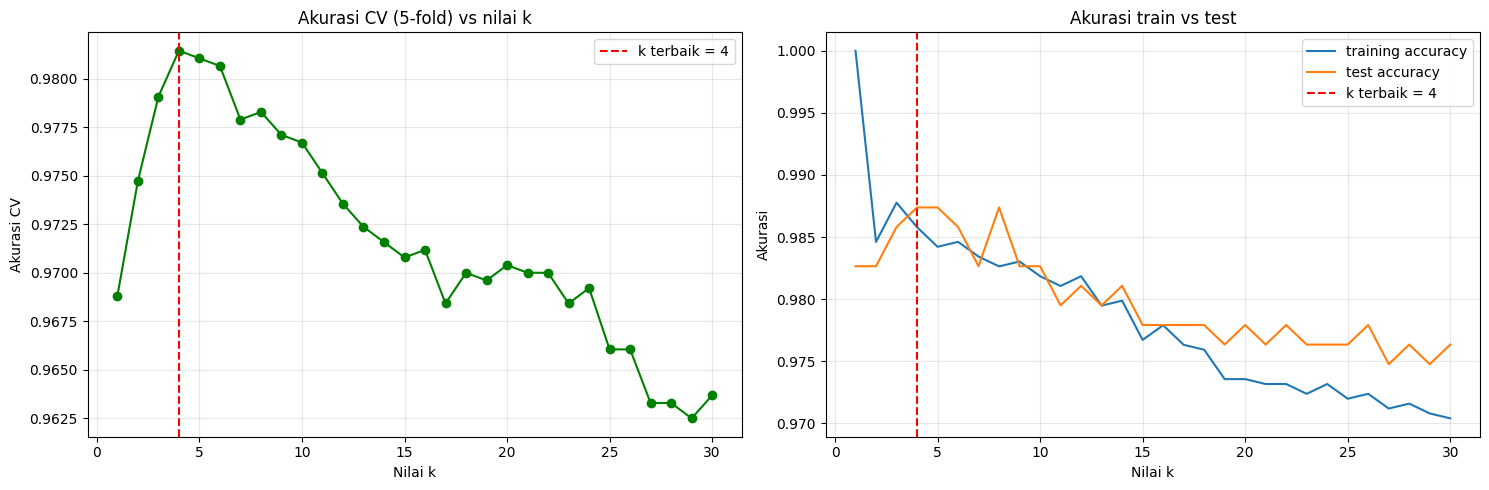

In [37]:
k_range = range(1, 31)
cv_k, train_k, test_k = [], [], []

for k in k_range:
    cv_k.append(cv_score(best_features, k=k))
    tr, te, _ = fit_eval(best_features, k=k)
    train_k.append(tr)
    test_k.append(te)

best_k = int(np.argmax(cv_k)) + 1
print(f'k terbaik berdasarkan CV: k = {best_k} (CV acc = {max(cv_k):.4f})')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(k_range, cv_k, marker='o', color='green')
axes[0].axvline(best_k, color='red', linestyle='--', label=f'k terbaik = {best_k}')
axes[0].set_title('Akurasi CV (5-fold) vs nilai k')
axes[0].set_xlabel('Nilai k'); axes[0].set_ylabel('Akurasi CV')
axes[0].grid(alpha=.3); axes[0].legend()

axes[1].plot(k_range, train_k, label='training accuracy')
axes[1].plot(k_range, test_k, label='test accuracy')
axes[1].axvline(best_k, color='red', linestyle='--', label=f'k terbaik = {best_k}')
axes[1].set_title('Akurasi train vs test')
axes[1].set_xlabel('Nilai k'); axes[1].set_ylabel('Akurasi')
axes[1].grid(alpha=.3); axes[1].legend()

plt.tight_layout()
plt.show()

In [38]:
pd.DataFrame({'k': list(k_range),
              'CV acc': np.round(cv_k, 4),
              'Train acc': np.round(train_k, 4),
              'Test acc': np.round(test_k, 4)}).set_index('k').T

k,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
CV acc,0.9688,0.9747,0.9791,0.9814,0.9811,0.9807,0.9779,0.9783,0.9771,0.9767,...,0.9700,0.9700,0.9684,0.9692,0.9661,0.9661,0.9633,0.9633,0.9625,0.9637
Train acc,1.0000,0.9846,0.9878,0.9858,0.9842,0.9846,0.9834,0.9826,0.9830,0.9818,...,0.9732,0.9732,0.9724,0.9732,0.9720,0.9724,0.9712,0.9716,0.9708,0.9704
Test acc,0.9826,0.9826,0.9858,0.9874,0.9874,0.9858,0.9826,0.9874,0.9826,0.9826,...,0.9763,0.9779,0.9763,0.9763,0.9763,0.9779,0.9748,0.9763,0.9748,0.9763


## 1.5 Evaluasi model akhir pada data test

Fitur (5): ['meanfun', 'IQR', 'sfm', 'mode', 'skew']
k = 4
Akurasi train : 0.9858
Akurasi test  : 0.9874

              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



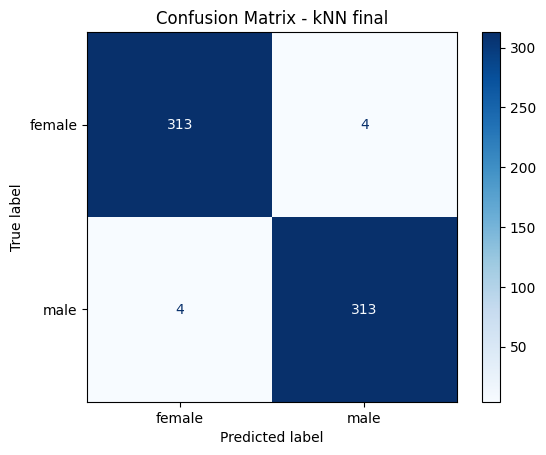

In [39]:
tr, te, final_model = fit_eval(best_features, k=best_k)
y_pred = final_model.predict(X_test[best_features])

print(f'Fitur ({len(best_features)}): {best_features}')
print(f'k = {best_k}')
print(f'Akurasi train : {tr:.4f}')
print(f'Akurasi test  : {te:.4f}\n')
print(classification_report(y_test, y_pred, target_names=['female', 'male']))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['female', 'male']).plot(cmap='Blues')
plt.title('Confusion Matrix - kNN final')
plt.show()

In [40]:
# Perbandingan akhir: baseline (20 fitur, k=5) vs model terpilih
_, te_base, _ = fit_eval(all_features, k=5)
print(f'Baseline  (20 fitur, k=5)            : test acc = {te_base:.4f}')
print(f'Terpilih  ({len(best_features)} fitur, k={best_k})  : test acc = {te:.4f}')

Baseline  (20 fitur, k=5)            : test acc = 0.9763
Terpilih  (5 fitur, k=4)  : test acc = 0.9874


## Jawaban Tugas 1

**No. 1 - Model kNN**  
Model kNN dibangun untuk mengklasifikasikan suara `male` dan `female` pada `voice.csv` (3168 data, 20 fitur, kelas seimbang 1584:1584, tidak ada missing value). Data dibagi 80:20 (`stratify`), fitur distandardisasi (wajib untuk kNN karena berbasis jarak), dan model awal memakai **semua 20 fitur dengan k=5**: akurasi test **0,9763** (15 kesalahan dari 634 data uji).

**No. 2 - Fitur paling optimal**  
Fitur terbaik hasil percobaan (*forward selection* dengan cross-validation 5-fold pada data train) adalah **`meanfun`, `IQR`, `sfm`, `mode`, `skew`** (5 fitur).

| Set fitur | Jumlah fitur | Akurasi CV | Akurasi test |
|---|---|---|---|
| Semua fitur | 20 | 0,9696 | 0,9763 |
| Top-9 mutual information | 9 | 0,9791 | 0,9795 |
| **Forward selection** | **5** | **0,9811** | **0,9874** |

Alasan:
- `meanfun` (rata-rata frekuensi fundamental) adalah fitur paling berpengaruh: peringkat 1 pada mutual information dan sendirian sudah mencapai akurasi CV 0,9408.
- Menambah `IQR` (0,9680), `sfm` (0,9767), dan `mode` (0,9807) menaikkan akurasi secara signifikan. Mulai fitur ke-5 (`skew`, 0,9811) kenaikannya sangat kecil, sehingga 5 fitur sudah cukup.
- Menambah fitur setelah itu tidak membantu, bahkan akurasi turun hingga 0,9696 pada 20 fitur. Fitur yang tersisa bersifat redundan atau noise (misalnya `meanfreq` dan `centroid` bernilai identik), padahal kNN menghitung jarak pada semua fitur sehingga fitur tidak informatif ikut mengganggu.
- Hasil akhir: akurasi test naik dari 0,9763 menjadi **0,9874** dengan fitur yang lebih sedikit (kesalahan turun dari 15 menjadi 8 data).

**No. 3 - Nilai k terbaik**  
Berdasarkan akurasi cross-validation pada 5 fitur terpilih, **k = 4** adalah yang terbaik (CV 0,9814; akurasi test 0,9874).

Alasan (lihat grafik CV vs k dan train vs test):
- **k terlalu kecil -> overfitting.** Pada k=1 akurasi train 1,0000 tetapi CV hanya 0,9688, karena model terlalu sensitif terhadap noise pada satu tetangga.
- **k terlalu besar -> underfitting.** Akurasi train, CV, dan test turun terus sampai k=30 (CV 0,9637) karena batas keputusan menjadi terlalu halus.
- Puncak akurasi CV berada di k=4 sampai 6 (0,9814; 0,9811; 0,9807), yaitu titik keseimbangan antara overfitting dan underfitting.
- Perbedaan k=4, 5, dan 6 sangat kecil (di bawah 0,1%). Karena k=4 genap dan dapat menghasilkan voting seri, **k=5** layak dipakai sebagai alternatif dengan akurasi test yang sama (0,9874).

---
# Tugas 2 - Multinomial Naive Bayes pada `spam.csv`
- **2a** : `CountVectorizer` dengan `stop_words`
- **2b** : `TF-IDF` dengan `stop_words`, bandingkan dengan 2a, dan simpulkan fitur terbaik

Ketiga model di Tugas 2 memakai split yang sama (`test_size=0.2`, `random_state=42`) agar perbandingan adil. Split ini berbeda dari Praktikum 3 (`random_state=50`), sehingga angka pembanding *tanpa stop_words* di sini sedikit berbeda dari Praktikum 3. Karena data tidak seimbang (ham 4825 vs spam 747), selain akurasi juga dilihat **precision, recall, dan F1 untuk kelas spam**.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

sms = pd.read_csv('spam.csv', encoding='latin-1').iloc[:, :2]
sms.columns = ['Labels', 'SMS']
sms['Labels'] = sms['Labels'].map({'spam': 1, 'ham': 0})

X_txt = sms['SMS'].values
y_txt = sms['Labels'].values

Xtr_txt, Xte_txt, ytr, yte = train_test_split(X_txt, y_txt, test_size=0.2, random_state=42)
print('Train:', len(Xtr_txt), '| Test:', len(Xte_txt))
print('Spam di train:', ytr.sum(), '| Spam di test:', yte.sum())

hasil = []

def evaluasi(nama, vec):
    """Fit vectorizer pada train, latih MultinomialNB, tampilkan dan simpan hasil evaluasi."""
    Xtr = vec.fit_transform(Xtr_txt)
    Xte = vec.transform(Xte_txt)
    model = MultinomialNB().fit(Xtr, ytr)
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)

    print(f'===== {nama} =====')
    print('Jumlah fitur (kosakata):', Xtr.shape[1])
    print(f'Akurasi train: {accuracy_score(ytr, p_tr):.4f}')
    print(f'Akurasi test : {accuracy_score(yte, p_te):.4f}\n')
    print(classification_report(yte, p_te, target_names=['ham', 'spam']))

    ConfusionMatrixDisplay(confusion_matrix(yte, p_te), display_labels=['ham', 'spam']).plot(cmap='Blues')
    plt.title(f'Confusion Matrix - {nama}')
    plt.show()

    hasil.append({
        'Model': nama, 'Jumlah fitur': Xtr.shape[1],
        'Acc train': accuracy_score(ytr, p_tr), 'Acc test': accuracy_score(yte, p_te),
        'Precision (spam)': precision_score(yte, p_te), 'Recall (spam)': recall_score(yte, p_te),
        'F1 (spam)': f1_score(yte, p_te)})
    return model, vec

Train: 4457 | Test: 1115
Spam di train: 597 | Spam di test: 150


## Tugas 2a - CountVectorizer + stop_words

===== Count (tanpa stop_words) =====
Jumlah fitur (kosakata): 7735
Akurasi train: 0.9944
Akurasi test : 0.9839

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       965
        spam       0.99      0.89      0.94       150

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



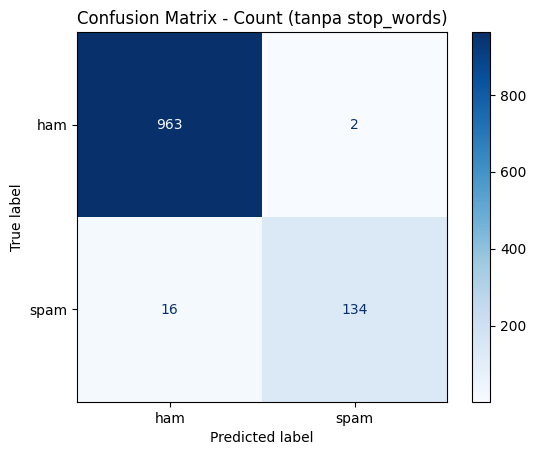

In [42]:
# Pembanding: CountVectorizer tanpa stop_words (Praktikum 3)
_ = evaluasi('Count (tanpa stop_words)', CountVectorizer())

===== Count + stop_words =====
Jumlah fitur (kosakata): 7472
Akurasi train: 0.9946
Akurasi test : 0.9839

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       965
        spam       0.96      0.92      0.94       150

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



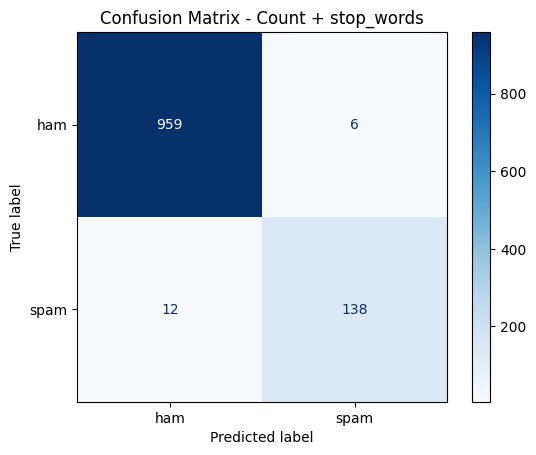

In [43]:
# Tugas 2a: CountVectorizer dengan stop_words='english'
model_cv, vec_cv = evaluasi('Count + stop_words', CountVectorizer(stop_words='english'))

### Analisis 2a (CountVectorizer + stop_words)
Dengan `stop_words='english'` kosakata turun dari 7735 menjadi 7472 kata (stop words dibuang). Akurasi test tetap **0,9839**, sama dengan tanpa stop_words, tetapi komposisi kesalahannya berubah:

| | Spam lolos (FN) | Ham salah jadi spam (FP) | Recall spam | Precision spam |
|---|---|---|---|---|
| Tanpa stop_words | 16 | 2 | 0,8933 | 0,9853 |
| Dengan stop_words | 12 | 6 | 0,9200 | 0,9583 |

Stop words membuat model lebih sensitif terhadap spam: 4 spam tambahan terdeteksi, tetapi 4 ham tambahan ikut salah ditandai. Pengaruhnya kecil, karena kata penentu spam seperti `claim`, `prize`, `uk`, `150p`, dan `tone` tidak termasuk stop words.

## Tugas 2b - TF-IDF + stop_words

===== TF-IDF + stop_words =====
Jumlah fitur (kosakata): 7472
Akurasi train: 0.9838
Akurasi test : 0.9668

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       965
        spam       1.00      0.75      0.86       150

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



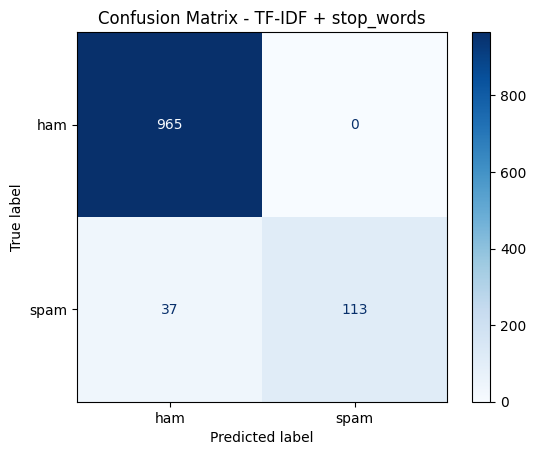

In [44]:
# Tugas 2b: TF-IDF dengan stop_words='english'
model_tf, vec_tf = evaluasi('TF-IDF + stop_words', TfidfVectorizer(stop_words='english'))

### Analisis 2b (TF-IDF + stop_words) dan perbandingan dengan 2a

| Model | Acc test | Precision spam | Recall spam | F1 spam | Spam lolos (FN) | Ham salah (FP) |
|---|---|---|---|---|---|---|
| Count + stop_words | **0,9839** | 0,9583 | **0,9200** | **0,9388** | 12 | 6 |
| TF-IDF + stop_words | 0,9668 | **1,0000** | 0,7533 | 0,8593 | 37 | 0 |

- TF-IDF menghasilkan **precision sempurna** (tidak ada SMS normal yang salah ditandai spam), tetapi **recall turun menjadi 0,7533**: 37 dari 150 SMS spam lolos, tiga kali lebih banyak daripada Count (12).
- Akibatnya akurasi dan F1 spam TF-IDF lebih rendah dari Count (0,9668 vs 0,9839 dan 0,8593 vs 0,9388).
- Dugaan penyebab: nilai TF-IDF berupa pecahan kecil yang dinormalisasi per dokumen, sehingga smoothing bawaan MultinomialNB (`alpha=1`) menjadi relatif terlalu besar dan prediksi condong ke kelas ham yang mayoritas (sekitar 87%). Dugaan ini belum diuji (misalnya dengan menurunkan `alpha`).
- Kedua model memakai kata penanda spam yang hampir sama (`claim`, `prize`, `uk`, `150p`, `tone`, `guaranteed`), sehingga perbedaan performa berasal dari cara pembobotan, bukan dari kata yang dipelajari.

## Perbandingan dan kesimpulan

In [45]:
tabel = pd.DataFrame(hasil).set_index('Model').round(4)
tabel

,Jumlah fitur,Acc train,Acc test,Precision (spam),Recall (spam),F1 (spam)
Model,,,,,,
Count (tanpa stop_words),7735,0.9944,0.9839,0.9853,0.8933,0.9371
Count + stop_words,7472,0.9946,0.9839,0.9583,0.9200,0.9388
TF-IDF + stop_words,7472,0.9838,0.9668,1.0000,0.7533,0.8593


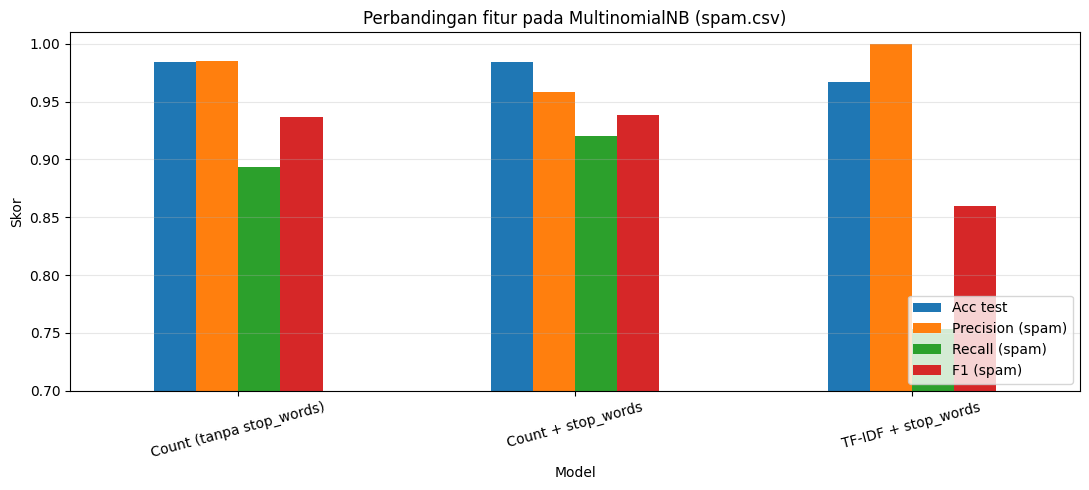

In [46]:
metrik = ['Acc test', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)']
tabel[metrik].plot(kind='bar', figsize=(11, 5))
plt.title('Perbandingan fitur pada MultinomialNB (spam.csv)')
plt.ylabel('Skor')
plt.ylim(0.7, 1.01)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.show()

In [47]:
# 10 kata dengan bobot tertinggi untuk kelas spam pada masing-masing fitur
for nama, mdl, vec in [('Count + stop_words', model_cv, vec_cv), ('TF-IDF + stop_words', model_tf, vec_tf)]:
    vocab = np.array(vec.get_feature_names_out())
    # selisih log probabilitas spam - ham = seberapa kuat kata menandai spam
    skor = mdl.feature_log_prob_[1] - mdl.feature_log_prob_[0]
    print(nama, '->', list(vocab[np.argsort(skor)[-10:][::-1]]))

Count + stop_words -> ['claim', 'prize', 'uk', '150p', 'tone', '18', 'guaranteed', 'cs', '500', '1000']
TF-IDF + stop_words -> ['claim', 'prize', 'uk', 'www', '150p', 'tone', 'guaranteed', '18', 'cs', '1000']


### Kesimpulan
Pada kasus `spam.csv`, fitur terbaik adalah **CountVectorizer dengan stop_words**.

- Fitur ini mencapai akurasi test **0,9839**, recall spam **0,92**, dan F1 spam **0,9388**, semuanya lebih tinggi dibanding TF-IDF + stop_words (akurasi 0,9668, recall 0,7533, F1 0,8593).
- TF-IDF unggul pada precision (1,0; tidak ada ham yang salah ditandai spam), tetapi 37 dari 150 spam lolos sehingga kurang andal sebagai filter spam. Count hanya meloloskan 12 spam dengan 6 ham yang salah ditandai.
- Penggunaan stop_words pada CountVectorizer tidak mengubah akurasi (tetap 0,9839); efeknya hanya menukar sedikit precision (0,9853 menjadi 0,9583) dengan recall yang lebih baik (0,8933 menjadi 0,9200). Karena itu F1 spam sedikit naik (0,9371 menjadi 0,9388).
- Catatan: jika prioritas utama adalah tidak boleh ada SMS normal yang salah terblokir, TF-IDF lebih aman, tetapi dengan konsekuensi lebih banyak spam yang lolos.